# Week 4
For Week 4, include concepts such as logistic regression and feature scaling. This homework should be submitted for peer review in the assignment titled 4.3 Peer Review: Week 4 Jupyter Notebook. Complete and submit your Jupyter Notebook homework by 11:59pm ET on Sunday. 

##### Import Libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import recall_score
import optuna
from optuna.visualization import (
    plot_optimization_history, 
    plot_param_importances, 
    plot_parallel_coordinate
)

##### Load Data

In [2]:
diabetes_indicators = pd.read_csv('Modified_Datasets/diabetes_indicators_2.csv')

In [3]:
cervical_cancer = pd.read_csv('Modified_Datasets/cervical_cancer_2.csv')

##### Logistic Regression & Feature Scaling

**Diabetes**

In [4]:
# X, y
Xd = diabetes_indicators.drop('Diabetes_012', axis = 1)
yd = diabetes_indicators['Diabetes_012']
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size = 0.2, random_state = 42)

In [5]:
# Scaler
scaler = StandardScaler()

In [6]:
# Transform
Xd_train_scaled = scaler.fit_transform(Xd_train)
Xd_test_scaled = scaler.transform(Xd_test)

In [7]:
model = LogisticRegression()

In [8]:
model.fit(Xd_train_scaled, yd_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [9]:
yd_pred = model.predict(Xd_test_scaled)

In [10]:
# Scoring
print(recall_score(yd_test, yd_pred, average = 'macro'))

0.38115689998698365


In [11]:
# KFold
kf = KFold(n_splits = 3,
           shuffle = True,
           random_state = 42)

In [12]:
# Scaler
scaler = StandardScaler()

In [13]:
# Transform
Xd_train_scaled = scaler.fit_transform(Xd_train)
Xd_test_scaled = scaler.transform(Xd_test)

In [14]:
# Hyperparameter tuning

# Create an objective function
def objective_function(trial): 
    params = {
        'C': trial.suggest_float('C', 1e-3, 1e3, log = True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'saga', 'newton-cg']),
        'max_iter': trial.suggest_int('max_iter', 100, 1000),
        'tol': trial.suggest_float('tol', 1e-5, 1e-2, log = True)
}

    model = LogisticRegression(**params)

    cv_scores = cross_val_score(
        model, 
        Xd_train_scaled, 
        yd_train, 
        cv = kf, 
        scoring = 'recall_weighted'
    )

    return cv_scores.mean()

# Set up Optuna study
study = optuna.create_study(direction = 'maximize')

study.optimize(objective_function, n_trials = 100)

# Display results
results = study.trials_dataframe()

results = results.sort_values(by = 'value', ascending = False)

display(results.head(5))

[I 2026-10-15 10:55:36,996] A new study created in memory with name: no-name-ea80c913-6ad6-4c20-ab33-98267138a41c
[I 2026-10-15 10:55:45,296] Trial 0 finished with value: 0.8311265142297181 and parameters: {'C': 0.003959853509537286, 'solver': 'saga', 'max_iter': 815, 'tol': 0.0003015328537117526}. Best is trial 0 with value: 0.8311265142297181.
[I 2026-10-15 10:55:48,302] Trial 1 finished with value: 0.83097419456046 and parameters: {'C': 49.912103615891404, 'solver': 'newton-cg', 'max_iter': 759, 'tol': 1.302344097599806e-05}. Best is trial 0 with value: 0.8311265142297181.
[I 2026-10-15 10:55:59,317] Trial 2 finished with value: 0.83097419456046 and parameters: {'C': 424.3882303620175, 'solver': 'saga', 'max_iter': 972, 'tol': 6.896837466347961e-05}. Best is trial 0 with value: 0.8311265142297181.
[I 2026-10-15 10:56:00,962] Trial 3 finished with value: 0.8309959543863813 and parameters: {'C': 14.737213417053216, 'solver': 'lbfgs', 'max_iter': 932, 'tol': 0.00023002531848048208}. Be

,number,value,datetime_start,datetime_complete,duration,params_C,params_max_iter,params_solver,params_tol,system_attrs_tpe:relative_params:0,state
60,60,0.831230,2026-10-15 11:01:34.062673,2026-10-15 11:01:35.047938,0 days 00:00:00.985265,0.003414,728,lbfgs,0.000987,"{""C"": 0.0034140213577355154, ""max_iter"": 728, ...",COMPLETE
51,51,0.831186,2026-10-15 11:00:46.037005,2026-10-15 11:00:47.560412,0 days 00:00:01.523407,0.001099,669,lbfgs,0.000178,"{""C"": 0.0010986474350576756, ""max_iter"": 669, ...",COMPLETE
66,66,0.831181,2026-10-15 11:01:59.860456,2026-10-15 11:02:01.701129,0 days 00:00:01.840673,0.001255,663,lbfgs,0.000068,"{""C"": 0.0012547272698630989, ""max_iter"": 663, ...",COMPLETE
85,85,0.831181,2026-10-15 11:02:34.661373,2026-10-15 11:02:36.244475,0 days 00:00:01.583102,0.001001,891,lbfgs,0.000222,"{""C"": 0.0010013072862727792, ""max_iter"": 891, ...",COMPLETE
43,43,0.831175,2026-10-15 11:00:14.364222,2026-10-15 11:00:15.856005,0 days 00:00:01.491783,0.001173,567,lbfgs,0.000197,"{""C"": 0.001173267498389511, ""max_iter"": 567, ""...",COMPLETE


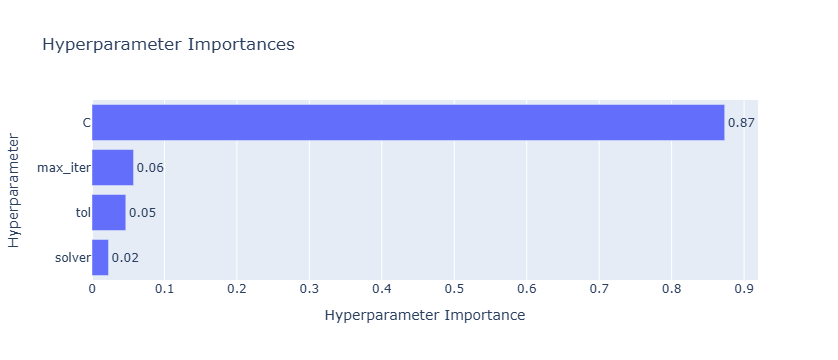

In [15]:
# Plot of which hyperparameters were the most important
plot_param_importances(study).show()

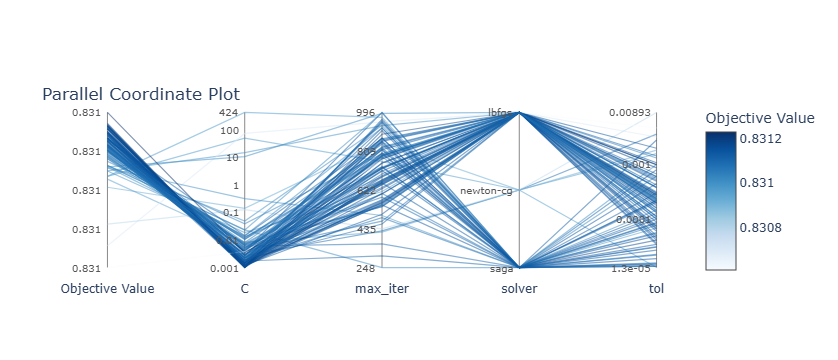

In [16]:
# Plot of parameter values vs objective score
plot_parallel_coordinate(study).show()

**Cervical Cancer**

In [17]:
# X, y
Xc = cervical_cancer.drop('Dx:Cancer', axis = 1)
yc = cervical_cancer['Dx:Cancer']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42)

In [18]:
# Scaler
scaler = StandardScaler()

In [19]:
# Transform
Xc_train_scaled = scaler.fit_transform(Xc_train)
Xc_test_scaled = scaler.transform(Xc_test)

In [20]:
model = LogisticRegression()

In [21]:
model.fit(Xc_train_scaled, yc_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [22]:
yc_pred = model.predict(Xc_test_scaled)

In [23]:
# Scoring
print(recall_score(yc_test, yc_pred))

0.6


In [24]:
# Hyperparameter tuning

# Create an objective function
def objective_function(trial): 
    params = {
        'C': trial.suggest_float('C', 1e-3, 1e3, log = True),
        'solver': trial.suggest_categorical('solver', ['lbfgs', 'saga', 'newton-cg']),
        'max_iter': trial.suggest_int('max_iter', 100, 1000),
        'tol': trial.suggest_float('tol', 1e-5, 1e-2, log = True)
}

    model = LogisticRegression(**params)

    cv_scores = cross_val_score(
        model, 
        Xc_train_scaled, 
        yc_train, 
        cv = kf, 
        scoring = 'recall_weighted'
    )

    return cv_scores.mean()

# Set up Optuna study
study = optuna.create_study(direction = 'maximize')

study.optimize(objective_function, n_trials = 100)

# Display results
results = study.trials_dataframe()

results = results.sort_values(by = 'value', ascending = False)

display(results.head(5))

[I 2026-10-15 11:03:05,181] A new study created in memory with name: no-name-9f5eb24f-abea-470e-9e68-bb55fff84686
C:\Users\golde\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\golde\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\golde\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
[I 2026-10-15 11:03:05,547] Trial 0 finished with value: 0.9961685823754789 and parameters: {'C': 6.14627482623756, 'solver': 'saga', 'max_iter': 524, 'tol': 1.3758689414522782e-05}. Best is trial 0 with value: 0.9961685823754789.
[I 2026-10-15 11:03:05,626] Tri

,number,value,datetime_start,datetime_complete,duration,params_C,params_max_iter,params_solver,params_tol,system_attrs_tpe:relative_params:0,state
0,0,0.996169,2026-10-15 11:03:05.198915,2026-10-15 11:03:05.547772,0 days 00:00:00.348857,6.146275,524,saga,0.000014,NaN,COMPLETE
1,1,0.996169,2026-10-15 11:03:05.547772,2026-10-15 11:03:05.626807,0 days 00:00:00.079035,111.006619,283,saga,0.003762,NaN,COMPLETE
7,7,0.996169,2026-10-15 11:03:05.864022,2026-10-15 11:03:05.895690,0 days 00:00:00.031668,19.495463,522,newton-cg,0.006773,NaN,COMPLETE
4,4,0.996169,2026-10-15 11:03:05.705960,2026-10-15 11:03:05.753761,0 days 00:00:00.047801,43.633409,971,newton-cg,0.002669,NaN,COMPLETE
34,34,0.996169,2026-10-15 11:03:08.268216,2026-10-15 11:03:08.300139,0 days 00:00:00.031923,75.588645,582,newton-cg,0.008645,"{""C"": 75.58864457704482, ""max_iter"": 582, ""sol...",COMPLETE


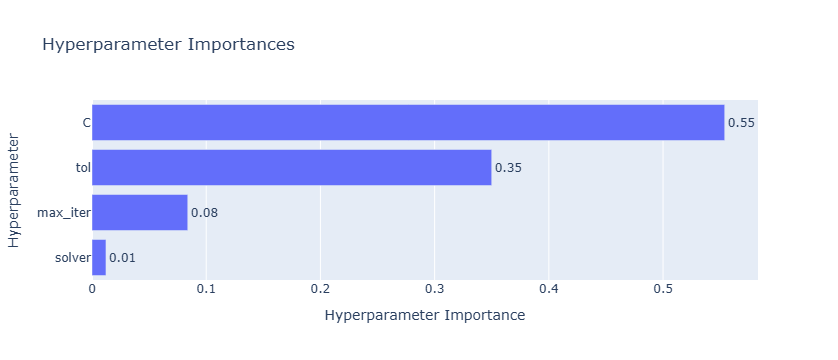

In [25]:
# Plot of which hyperparameters were the most important
plot_param_importances(study).show()

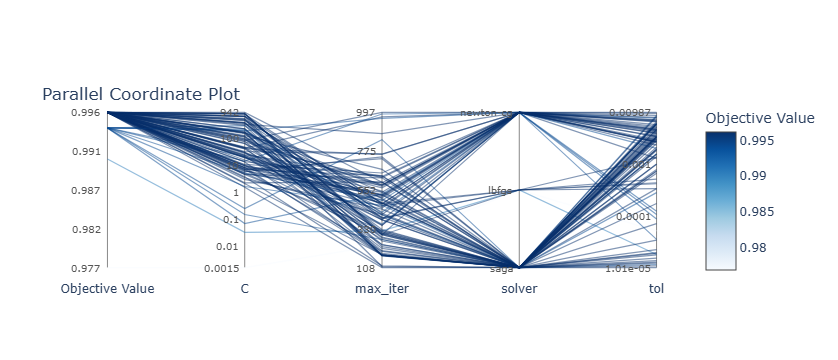

In [26]:
# Plot of parameter values vs objective score
plot_parallel_coordinate(study).show()